In [9]:
#ДЗ 
# 1. Для изображения sar_3.jpg найти наиболее протяженный участок
# (выделить линии при помощи преобразования Хафа)
# 2. Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
from copy import deepcopy

In [11]:
image = cv2.imread('sar_3.jpg')
image_line = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

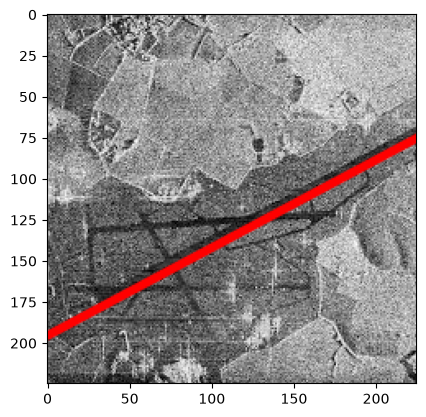

In [12]:
# наиболее протяженный участок через преобразование Хафа
canny = cv2.Canny(image_gray,130,400, apertureSize = 3)
lines = cv2.HoughLines(canny, 1, np.pi / 180, 120)

if lines is not None:
    for i in range(0, len(lines)):
        rho = lines[i][0][0]
        theta = lines[i][0][1]
        a = math.cos(theta)
        b = math.sin(theta)
        x0 = a * rho
        y0 = b * rho
        pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
        pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
        cv2.line(image_line, pt1, pt2, (255, 0, 0), 3, cv2.LINE_AA)

plt.imshow(image_line)

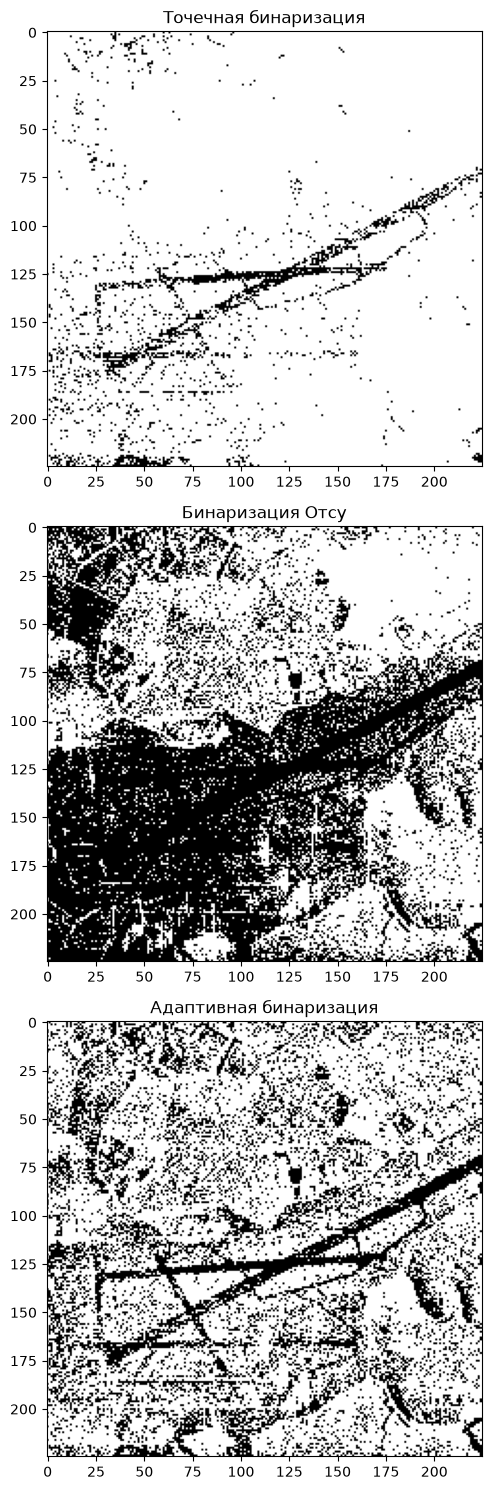

In [ ]:
# Бинаризации

fig, axes = plt.subplots(3, 1, figsize=(8, 15))

# 1. Точечная бинаризация
bin_img = deepcopy(image_gray)
T = 50
bin_img[image_gray < T] = 0
bin_img[image_gray >= T] = 255
axes[0].set_title('Точечная бинаризация')
axes[0].imshow(bin_img, cmap="gray")

# 2. Бинаризация Отсу
_, th2 = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
axes[1].set_title('Бинаризация Отсу')
axes[1].imshow(th2, cmap="gray")

# 3. Адаптивная бинаризация
th3 = cv2.adaptiveThreshold(image_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 71, 21)
axes[2].set_title('Адаптивная бинаризация')
axes[2].imshow(th3, cmap="gray")

plt.tight_layout()
plt.show()

